# Data Science Fundamentals Assessment
**Task 1 | Data Analyst Internship**

## Purpose
This notebook demonstrates Python fundamentals, basic statistical analysis, Pandas data exploration, visualization, data-quality checks, and reproducible cleaning practices. The datasets are synthetic examples created for learning; no real customer information is used.


## 1. Python fundamentals

In [1]:
student_name = "Sommay"
marks = [78, 85, 92, 67, 88]
total_marks = sum(marks)
average_marks = total_marks / len(marks)

print("Student:", student_name)
print("Marks:", marks)
print("Total marks:", total_marks)
print("Average marks:", round(average_marks, 2))

if average_marks >= 80:
    print("Performance: Excellent")
elif average_marks >= 60:
    print("Performance: Good")
else:
    print("Performance: Needs improvement")


Student: Sommay
Marks: [78, 85, 92, 67, 88]
Total marks: 410
Average marks: 82.0
Performance: Excellent


## 2. Core data types and collections

In [2]:
name = "Sommay"           # str
age = 22                  # int (example value for practice)
percentage = 82.0          # float (example value for practice)
is_passed = True           # bool
skills = ["Python", "SQL", "Power BI"]  # list
profile = {"name": name, "skills": skills, "passed": is_passed}  # dict

print(type(name), type(age), type(percentage), type(is_passed))
print(profile)


<class 'str'> <class 'int'> <class 'float'> <class 'bool'>
{'name': 'Sommay', 'skills': ['Python', 'SQL', 'Power BI'], 'passed': True}


## 3. NumPy and descriptive statistics

In [3]:
import numpy as np
from scipy import stats

marks = np.array([78, 85, 92, 67, 88, 85, 75, 90])
print("Mean:", np.mean(marks))
print("Median:", np.median(marks))
print("Mode:", stats.mode(marks, keepdims=False).mode)
print("Minimum:", np.min(marks))
print("Maximum:", np.max(marks))
print("Range:", np.ptp(marks))
print("Population variance:", round(np.var(marks), 2))
print("Population standard deviation:", round(np.std(marks), 2))


Mean: 82.5
Median: 85.0
Mode: 85
Minimum: 67
Maximum: 92
Range: 25
Population variance: 63.25
Population standard deviation: 7.95


## 4. Pandas exploration and aggregation

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Student": ["A", "B", "C", "D", "E", "F"],
    "Marks": [78, 85, 92, 67, 88, 85],
    "Department": ["Analytics", "IT", "Analytics", "IT", "Analytics", "IT"]
}
df = pd.DataFrame(data)

display(df.head())
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nSummary statistics:\n", df.describe())
print("\nDepartment averages:\n", df.groupby("Department")["Marks"].mean())


,Student,Marks,Department
0,A,78,Analytics
1,B,85,IT
2,C,92,Analytics
3,D,67,IT
4,E,88,Analytics


Shape: (6, 3)

Data types:
 Student         str
Marks         int64
Department      str
dtype: object

Summary statistics:
            Marks
count   6.000000
mean   82.500000
std     8.871302
min    67.000000
25%    79.750000
50%    85.000000
75%    87.250000
max    92.000000

Department averages:
 Department
Analytics    86.0
IT           79.0
Name: Marks, dtype: float64


## 5. Visualization

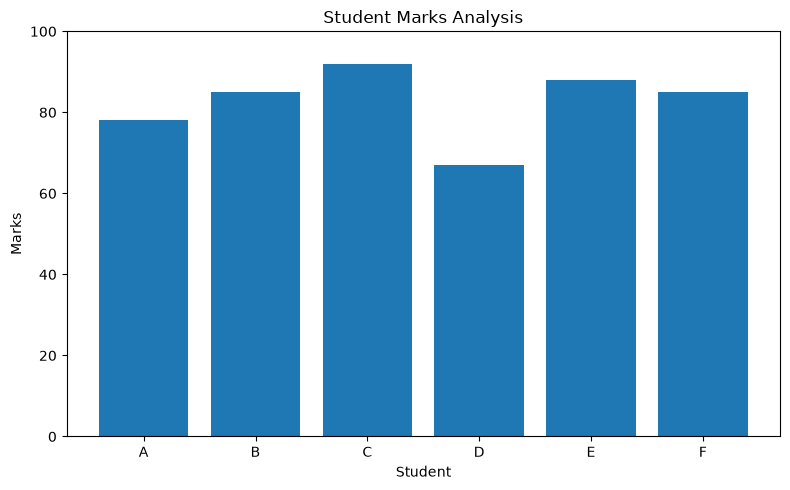

In [5]:
plt.figure(figsize=(8, 5))
plt.bar(df["Student"], df["Marks"])
plt.title("Student Marks Analysis")
plt.xlabel("Student")
plt.ylabel("Marks")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


## 6. Data quality assessment and cleaning

In [6]:
import numpy as np

raw_data = {
    "Customer_ID": [101, 102, 103, 104, 104, 106, 107],
    "Age": [25, 32, np.nan, 45, 45, 150, 29],
    "City": ["Delhi", "Gurugram", "Delhi", "Noida", "Noida", "Mumbai", "Delhi"],
    "Purchase_Amount": [1200, 2500, 1800, np.nan, np.nan, 3200, 1500]
}
raw_df = pd.DataFrame(raw_data)
print("Raw data:")
display(raw_df)
print("Missing values by column:\n", raw_df.isnull().sum())
print("Exact duplicate rows:", raw_df.duplicated().sum())

clean_df = raw_df.drop_duplicates().copy()
clean_df.loc[(clean_df["Age"] < 0) | (clean_df["Age"] > 100), "Age"] = np.nan
clean_df["Age"] = clean_df["Age"].fillna(clean_df["Age"].median())
clean_df["Purchase_Amount"] = clean_df["Purchase_Amount"].fillna(clean_df["Purchase_Amount"].median())

print("Cleaned data:")
display(clean_df)
print("Missing values after cleaning:\n", clean_df.isnull().sum())
print("Duplicate rows after cleaning:", clean_df.duplicated().sum())


Raw data:


,Customer_ID,Age,City,Purchase_Amount
0,101,25.0,Delhi,1200.0
1,102,32.0,Gurugram,2500.0
2,103,NaN,Delhi,1800.0
3,104,45.0,Noida,NaN
4,104,45.0,Noida,NaN
5,106,150.0,Mumbai,3200.0
6,107,29.0,Delhi,1500.0


Missing values by column:
 Customer_ID        0
Age                1
City               0
Purchase_Amount    2
dtype: int64
Exact duplicate rows: 1
Cleaned data:


,Customer_ID,Age,City,Purchase_Amount
0,101,25.0,Delhi,1200.0
1,102,32.0,Gurugram,2500.0
2,103,30.5,Delhi,1800.0
3,104,45.0,Noida,1800.0
5,106,30.5,Mumbai,3200.0
6,107,29.0,Delhi,1500.0


Missing values after cleaning:
 Customer_ID        0
Age                0
City               0
Purchase_Amount    0
dtype: int64
Duplicate rows after cleaning: 0


## 7. Validation checks and reusable function

In [7]:
assert clean_df["Customer_ID"].is_unique
assert clean_df["Age"].between(0, 100).all()
assert clean_df["Purchase_Amount"].ge(0).all()
assert clean_df.isnull().sum().sum() == 0
assert clean_df.duplicated().sum() == 0

def summarize_data(dataframe):
    """Return basic quality indicators for a pandas DataFrame."""
    return {
        "rows": len(dataframe),
        "columns": len(dataframe.columns),
        "missing_values": int(dataframe.isnull().sum().sum()),
        "duplicate_rows": int(dataframe.duplicated().sum())
    }

print("All data-quality checks passed.")
print(summarize_data(clean_df))


All data-quality checks passed.
{'rows': 6, 'columns': 4, 'missing_values': 0, 'duplicate_rows': 0}


## 8. Save outputs

In [8]:
from pathlib import Path
import json

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(results_dir / "cleaned_customer_data.csv", index=False)

quality_summary = {
    "rows_after_cleaning": int(len(clean_df)),
    "columns": int(len(clean_df.columns)),
    "missing_values_after_cleaning": int(clean_df.isnull().sum().sum()),
    "duplicate_rows_after_cleaning": int(clean_df.duplicated().sum()),
    "unique_customer_ids": bool(clean_df["Customer_ID"].is_unique),
    "age_range_valid": bool(clean_df["Age"].between(0, 100).all()),
    "purchase_amount_non_negative": bool(clean_df["Purchase_Amount"].ge(0).all())
}
with open(results_dir / "data_quality_summary.json", "w", encoding="utf-8") as file:
    json.dump(quality_summary, file, indent=2)

print("Cleaned dataset and quality summary saved.")


Cleaned dataset and quality summary saved.


## 9. Key takeaways and limitations
- Python variables, collections, conditional logic, and built-in functions support foundational analysis.
- NumPy provides efficient numerical operations; Pandas supports structured data inspection and aggregation.
- Visualizations communicate comparisons quickly, but should have clear titles and axis labels.
- Missing values, duplicates, invalid ranges, and identifier uniqueness should be investigated before analysis.
- Median imputation is used here only as a teaching example. Real projects require a reasoned decision based on missingness patterns and business context.
- The sample dataset is synthetic and very small; results should not be generalized to real customers.
